# Chapter 3

Python version of the R code for Chapter 3 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from helpers import DATA

## `EX3-9.R`

This script is headed "Section 9-10, Logistic model" and is the same as
`SEC9-10A.R` in Chapter 9.

In [2]:
x, y = np.loadtxt(DATA / "surgery.dat", unpack=True)
n = len(y)

# glm
x0 = x - x.mean()
xglm = sm.GLM(y, sm.add_constant(x0), family=sm.families.Binomial()).fit()

# Computing covariance matrix:
X = np.column_stack([np.ones(n), x0])  # design matrix
p = xglm.fittedvalues                   # fitted probabilities
W = p * (1 - p)                         # weight vector

XW = X * W[:, None]
XWX = XW.T @ X
print("The covariance matrix:")
print(np.linalg.inv(XWX))

print("From GLM")
print(xglm.cov_params())

The covariance matrix:
[[ 0.13520899 -0.00627764]
 [-0.00627764  0.00526934]]
From GLM
[[ 0.13520899 -0.00627764]
 [-0.00627764  0.00526934]]


## Example 3.10 (`EX3-10.R`)

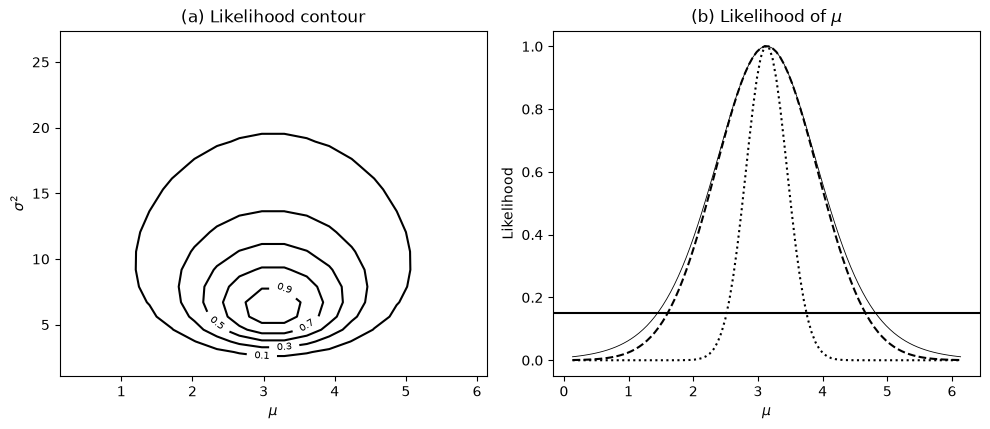

In [3]:
x = np.array([0.88, 1.07, 1.27, 1.54, 1.91, 2.27, 3.84, 4.5, 4.64, 9.41])
n = len(x)


def fun0(mu, sigma):
    """Minus log-likelihood of (mu, sigma) under the normal model."""
    a = (-n / 2 * np.log(sigma ** 2)
         - (np.sum(x ** 2) - 2 * mu * np.sum(x) + n * mu ** 2) / (2 * sigma ** 2))
    return -a


fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

np_ = 20
mu = np.linspace(x.mean() - 3, x.mean() + 3, np_)
sx = np.std(x, ddof=1)
sigma = np.linspace(sx / 2.5, sx * 2, np_)

ll2 = fun0(mu[:, None], sigma[None, :])
like2 = np.exp(ll2.min() - ll2)
ax = axes[0]
cs = ax.contour(mu, sigma ** 2, like2.T, levels=[.1, .3, .5, .7, .9], colors="k")
ax.clabel(cs, fontsize=7)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel(r"$\sigma^2$")
ax.set_title("(a) Likelihood contour")

# profile likelihood
np_ = 100
mu = np.linspace(x.mean() - 3, x.mean() + 3, np_)
ll = []
for mui in mu:
    shat2 = np.sum((x - mui) ** 2) / n
    ll.append(-n / 2 * np.log(shat2))
ll = np.array(ll)

like = np.exp(ll - ll.max())
ax = axes[1]
ax.plot(mu, like, "k-", lw=0.6)
ax.axhline(.15, color="k")
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(b) Likelihood of $\mu$")

ll = fun0(mu, sigma=1)
like = np.exp(ll.min() - ll)
ax.plot(mu, like, "k:", lw=1.5)

se = np.sqrt(np.var(x, ddof=1) * (n - 1) / n) / np.sqrt(n)
xbar = x.mean()
elike = stats.norm.pdf(xbar, loc=mu, scale=se)
elike = elike / elike.max()
ax.plot(mu, elike, "k--")

axes[2].set_visible(False)
axes[3].set_visible(False)
fig.tight_layout()
plt.show()